<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 15: BPTT Flow and Gradient Analysis
In this notebook, we will trace Backpropagation Through Time (BPTT) step-by-step. By manually unrolling the forward pass and using `tf.GradientTape`, we will measure and plot the gradient norm of the loss with respect to the hidden state at each individual time step. We will analyze how these gradients vanish or explode over various sequence lengths (10, 50, 100) and compare `tanh` vs. `ReLU` activations.

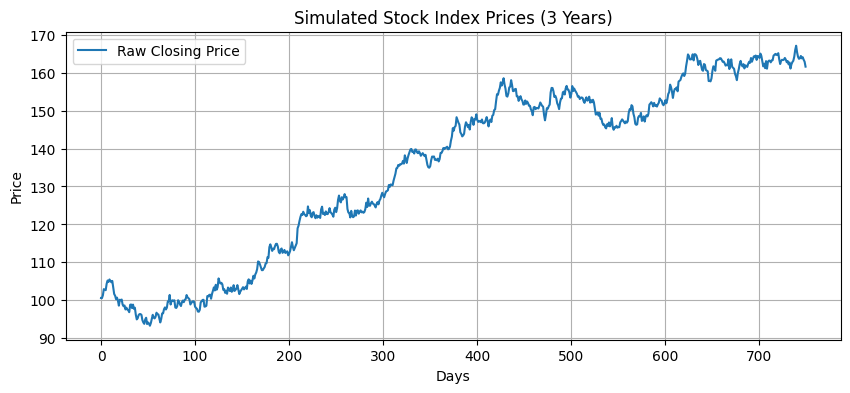

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Simulate 3 years of daily closing prices (approx. 750 trading days)
time_steps = 750
time = np.arange(time_steps)
# Simulate a random walk with trend
prices = 100.0 + np.cumsum(np.random.normal(0.1, 1.0, size=time_steps))

# Normalize prices to keep training stable
prices_min, prices_max = prices.min(), prices.max()
prices_norm = (prices - prices_min) / (prices_max - prices_min)

plt.figure(figsize=(10, 4))
plt.plot(time, prices, label='Raw Closing Price')
plt.title('Simulated Stock Index Prices (3 Years)')
plt.xlabel('Days')
plt.ylabel('Price')
plt.grid(True)
plt.legend()
plt.show()

In [2]:
def create_sequences(data, seq_length):
    """Generates inputs and target pairs for sequence prediction."""
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X)[..., np.newaxis], np.array(y)[..., np.newaxis]

# Preview sequence creation
X_preview, y_preview = create_sequences(prices_norm, 10)
print("Sequence Input Shape (N, Seq_Len, Features):", X_preview.shape)
print("Target Shape (N, Features):", y_preview.shape)

Sequence Input Shape (N, Seq_Len, Features): (740, 10, 1)
Target Shape (N, Features): (740, 1)


In [3]:
class SimpleRNNBPTT(tf.keras.Model):
    def __init__(self, units=1, activation='tanh', init_scale=1.0):
        super(SimpleRNNBPTT, self).__init__()
        self.units = units
        self.activation = tf.keras.activations.get(activation)

        # Custom weight initialization to help demonstrate gradient patterns clearly
        self.W_hh = tf.Variable(tf.random.normal([units, units], mean=0.0, stddev=init_scale), name='W_hh')
        self.W_xh = tf.Variable(tf.random.normal([1, units], mean=0.0, stddev=init_scale), name='W_xh')
        self.b_h = tf.Variable(tf.zeros([units]), name='b_h')

        self.W_hy = tf.Variable(tf.random.normal([units, 1], mean=0.0, stddev=init_scale), name='W_hy')
        self.b_y = tf.Variable(tf.zeros([1]), name='b_y')

    def call_and_trace(self, x):
        """
        Performs forward pass step-by-step while recording hidden states
        so we can compute gradients back to each individual step.
        """
        batch_size = tf.shape(x)[0]
        seq_len = tf.shape(x)[1]

        # Initialize hidden state
        h = tf.zeros([batch_size, self.units])
        h_states = []

        # We manually unroll the loop to explicitly track operations for BPTT
        for t in range(seq_len):
            x_t = x[:, t, :]
            # Compute state transition
            h = self.activation(tf.matmul(x_t, self.W_xh) + tf.matmul(h, self.W_hh) + self.b_h)
            h_states.append(h)

        # Final output prediction
        y_pred = tf.matmul(h, self.W_hy) + self.b_y
        return y_pred, h_states

In [4]:
def analyze_gradients(seq_length, activation='tanh', init_scale=1.1):
    # Prepare sequences
    X, y = create_sequences(prices_norm, seq_length)
    X_tf = tf.convert_to_tensor(X, dtype=tf.float32)
    y_tf = tf.convert_to_tensor(y, dtype=tf.float32)

    # Instantiate model
    model = SimpleRNNBPTT(units=1, activation=activation, init_scale=init_scale)

    with tf.GradientTape(persistent=True) as tape:
        # Forward pass tracking state steps
        y_pred, h_states = model.call_and_trace(X_tf)
        loss = tf.reduce_mean(tf.square(y_pred - y_tf)) # MSE Loss

    # Compute gradient of loss with respect to each step's hidden state h_t
    grad_norms = []
    for t in range(seq_length):
        grad_h_t = tape.gradient(loss, h_states[t])
        # Calculate average gradient norm across the batch
        norm = tf.reduce_mean(tf.norm(grad_h_t, axis=-1)).numpy()
        grad_norms.append(norm)

    del tape # Clean up persistent tape
    return grad_norms

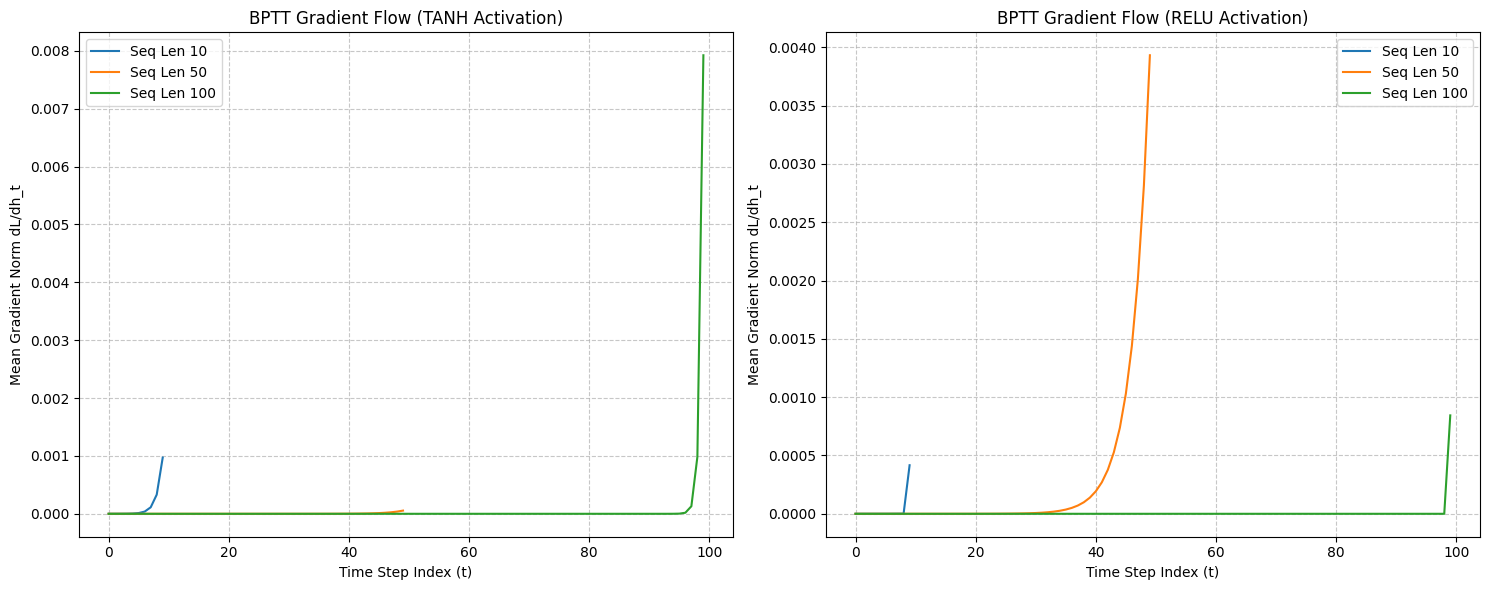

In [5]:
# 3 & 4. Plot gradient norm against time step for each sequence length and activation
seq_lengths = [10, 50, 100]
activations = ['tanh', 'relu']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for i, act in enumerate(activations):
    ax = axes[i]
    for seq_len in seq_lengths:
        # Use a higher initial scale for ReLU to showcase potential exploding gradient patterns if untreated
        init_scale = 1.05 if act == 'tanh' else 1.15
        norms = analyze_gradients(seq_length=seq_len, activation=act, init_scale=init_scale)

        # Normalize time step indices backwards from final step (t = 0 is far past, t = seq_len-1 is immediate past)
        time_steps_back = list(range(seq_len))
        ax.plot(time_steps_back, norms, label=f'Seq Len {seq_len}')

    ax.set_title(f'BPTT Gradient Flow ({act.upper()} Activation)')
    ax.set_xlabel('Time Step Index (t)')
    ax.set_ylabel('Mean Gradient Norm dL/dh_t')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend()

plt.tight_layout()
plt.show()

### 5. Discussion: Vanishing vs. Exploding Gradients

- **Vanishing Gradients (Typically observed in `tanh`):** As we propagate the gradient back in time (moving left from $t=99$ to $t=0$), we observe that the gradient norm approaches 0 rapidly. This happens because the derivative of the `tanh` function is strictly less than 1 ($|\tanh'(x)| \le 1$), and repeated multiplications by recurrent weights smaller than 1 contract the gradient exponential-wise. Consequently, the network fails to learn dependencies spanning further back than a few steps.
- **Exploding Gradients (Commonly observed in `ReLU`):** Since the derivative of `ReLU` is 1 for positive inputs, the backpropagated gradient is not scaled down by the activation function derivative. If the recurrent weight scale is even slightly larger than 1.0, repeated matrix multiplications lead to exponential growth of the gradient norms as we trace further back into the past. This causes training instability or numeric overflows.